In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, roc_auc_score

In [ ]:
#define column names
data=pd.read_csv("wdbc.data",header=None)
columns=[
    "id", "diagnosis",
    "radius_mean", "texture_mean", "perimeter_mean", "area_mean",
    "smoothness_mean", "compactness_mean", "concavity_mean",
    "concave_points_mean", "symmetry_mean", "fractal_dimension_mean",
    "radius_se", "texture_se", "perimeter_se", "area_se",
    "smoothness_se", "compactness_se", "concavity_se",
    "concave_points_se", "symmetry_se", "fractal_dimension_se",
    "radius_worst", "texture_worst", "perimeter_worst", "area_worst",
    "smoothness_worst", "compactness_worst", "concavity_worst",
    "concave_points_worst", "symmetry_worst", "fractal_dimension_worst"
]
data.columns=columns

In [ ]:
#dataset info
print("First 5 rows:")
print(data.head())

print("\nDataset Shape:")
print(data.shape)

print("\nColumn Names:")
print(data.columns)

print("\nData Types:")
print(data.dtypes)

print("\nMissing Values:")
print(data.isnull().sum())

print("\nDuplicate Rows:")
print(data.duplicated().sum())

print("\nStatistical Summary:")
print(data.describe())

First 5 rows:
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave_points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  radius_worst  texture_worst  perimeter_w


Class Distribution:
diagnosis
B    357
M    212
Name: count, dtype: int64

Class Distribution Percentage:
diagnosis
B    62.741652
M    37.258348
Name: proportion, dtype: float64


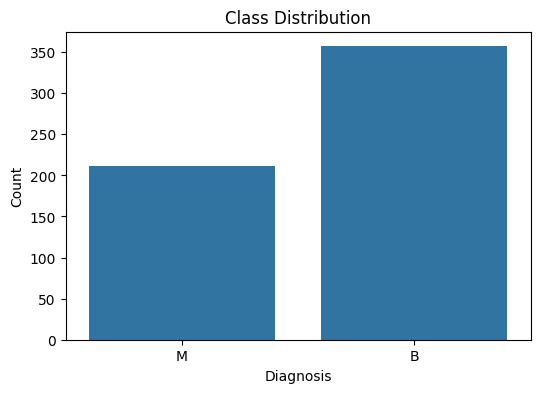

In [ ]:
#class distribution and its plot
print("\nClass Distribution:")
print(data["diagnosis"].value_counts())

print("\nClass Distribution Percentage:")
print(data["diagnosis"].value_counts(normalize=True) * 100)

plt.figure(figsize=(6, 4))
sns.countplot(x="diagnosis",data=data)
plt.xlabel("Diagnosis")
plt.ylabel("Count")
plt.title("Class Distribution")
plt.show()

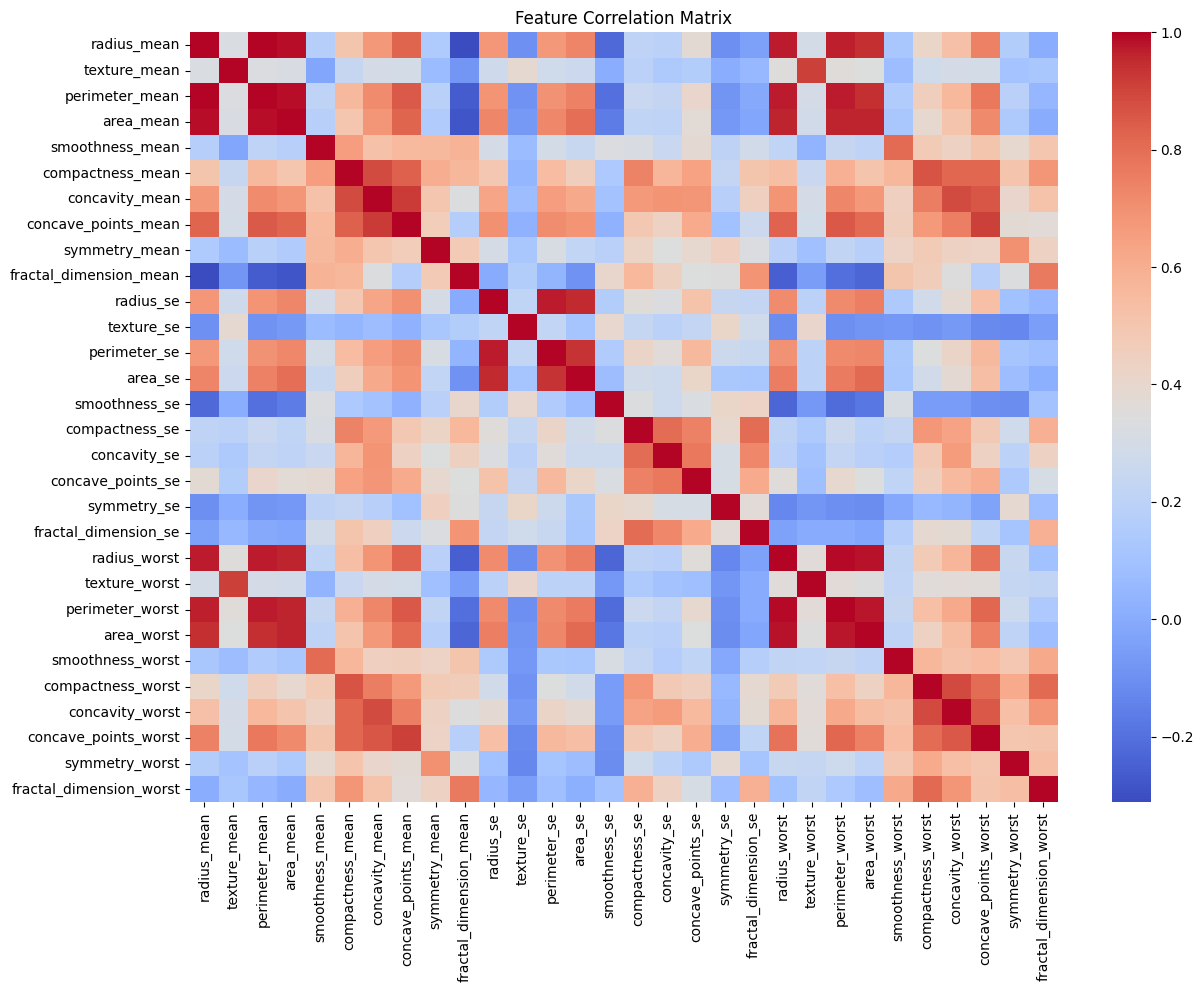

In [ ]:
#correlation analysis
features = data.drop(columns=["id","diagnosis"])
plt.figure(figsize=(14,10))
sns.heatmap(features.corr(), cmap="coolwarm")
plt.title("Feature Correlation Matrix")
plt.show()

In [ ]:
#encode target,x,y
data["diagnosis"]=data["diagnosis"].map({"M": 1,"B": 0})

X=data.drop(columns=["id","diagnosis"])
y=data["diagnosis"]

print("Feature Shape:",X.shape)
print("Target Shape:",y.shape)

#train test split
X_train, X_test, y_train, y_test=train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print("Training Data:",X_train.shape)
print("Testing Data:",X_test.shape)

#5 fold cross validation setup
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

Feature Shape: (569, 30)
Target Shape: (569,)
Training Data: (455, 30)
Testing Data: (114, 30)


/tmp/ipykernel_3134/2709378901.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dt_table["Avg CV Accuracy"]=dt_table["Avg CV Accuracy"]*100
/tmp/ipykernel_3134/2709378901.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dt_table["Avg CV F1 Score"]=dt_table["Avg CV F1 Score"]*100


Decision Tree Hyperparameter Evaluation
   Criterion Max Depth  Min Samples Split  Min Samples Leaf  Avg CV Accuracy  \
0       gini         3                  2                 1        92.087912   
1       gini         3                  5                 1        92.087912   
2       gini         3                 10                 1        92.087912   
3       gini         3                  2                 2        92.087912   
4       gini         3                  5                 2        92.087912   
..       ...       ...                ...               ...              ...   
85   entropy      None                  5                 2        92.967033   
86   entropy      None                 10                 2        93.406593   
87   entropy      None                  2                 4        92.527473   
88   entropy      None                  5                 4        92.527473   
89   entropy      None                 10                 4        92.747253   


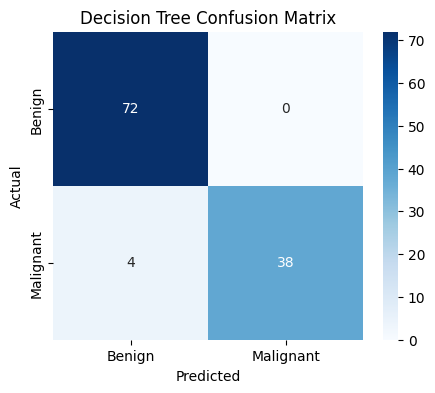

In [ ]:
#Decision Tree
dt=DecisionTreeClassifier(random_state=42)
dt_params={"criterion": ["gini", "entropy"],"max_depth": [3, 5, 7, 10, None],"min_samples_split": [2, 5, 10],"min_samples_leaf": [1, 2, 4]}
dt_grid=GridSearchCV(dt,dt_params,cv=cv,scoring={"accuracy": "accuracy","f1": "f1"},refit="accuracy",n_jobs=-1)
dt_grid.fit(X_train, y_train)

dt_cv_results=pd.DataFrame(dt_grid.cv_results_)
dt_table=dt_cv_results[["param_criterion","param_max_depth","param_min_samples_split","param_min_samples_leaf",
        "mean_test_accuracy","mean_test_f1"]]
dt_table.columns=["Criterion","Max Depth","Min Samples Split","Min Samples Leaf","Avg CV Accuracy","Avg CV F1 Score"]
dt_table["Avg CV Accuracy"]=dt_table["Avg CV Accuracy"]*100
dt_table["Avg CV F1 Score"]=dt_table["Avg CV F1 Score"]*100
print("Decision Tree Hyperparameter Evaluation")
print(dt_table)

dt_best=dt_grid.best_estimator_

dt_pred=dt_best.predict(X_test)
dt_accuracy=accuracy_score(y_test, dt_pred)
dt_precision=precision_score(y_test, dt_pred)
dt_recall=recall_score(y_test, dt_pred)
dt_f1=f1_score(y_test, dt_pred)
print("Decision Tree Test Results")
print("Accuracy:",dt_accuracy)
print("Precision:",dt_precision)
print("Recall:",dt_recall)
print("F1 Score:",dt_f1)

dt_cm=confusion_matrix(y_test, dt_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(dt_cm,annot=True,fmt="d",cmap="Blues",xticklabels=["Benign", "Malignant"],yticklabels=["Benign", "Malignant"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")
plt.show()

Random Forest Hyperparameter Evaluation
    N Estimators Max Depth Max Features  Bootstrap  Avg CV Accuracy  \
0             50         3         sqrt       True        95.824176   
1            100         3         sqrt       True        95.604396   
2            200         3         sqrt       True        95.604396   
3             50         3         log2       True        95.384615   
4            100         3         log2       True        95.824176   
5            200         3         log2       True        95.164835   
6             50         5         sqrt       True        96.263736   
7            100         5         sqrt       True        96.703297   
8            200         5         sqrt       True        95.604396   
9             50         5         log2       True        95.824176   
10           100         5         log2       True        96.043956   
11           200         5         log2       True        96.043956   
12            50         7         sq

/tmp/ipykernel_3134/3698309780.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  rf_table["Avg CV Accuracy"]=rf_table["Avg CV Accuracy"]*100
/tmp/ipykernel_3134/3698309780.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  rf_table["Avg CV F1 Score"]=rf_table["Avg CV F1 Score"]*100


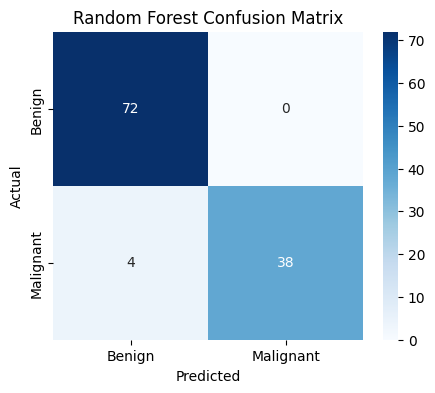

In [ ]:
#Random Forest
rf=RandomForestClassifier(random_state=42)
rf_params={"n_estimators": [50, 100, 200],"max_depth": [3, 5, 7, 10, None],"max_features": ["sqrt", "log2"],"bootstrap": [True, False]}
rf_grid=GridSearchCV(rf,rf_params,cv=cv,scoring={"accuracy": "accuracy","f1": "f1"},refit="accuracy",n_jobs=-1)
rf_grid.fit(X_train, y_train)

rf_cv_results=pd.DataFrame(rf_grid.cv_results_)
rf_table=rf_cv_results[["param_n_estimators","param_max_depth","param_max_features","param_bootstrap",
        "mean_test_accuracy","mean_test_f1"]]
rf_table.columns=["N Estimators","Max Depth","Max Features","Bootstrap","Avg CV Accuracy","Avg CV F1 Score"]
rf_table["Avg CV Accuracy"]=rf_table["Avg CV Accuracy"]*100
rf_table["Avg CV F1 Score"]=rf_table["Avg CV F1 Score"]*100
print("Random Forest Hyperparameter Evaluation")
print(rf_table)


rf_best=rf_grid.best_estimator_

rf_pred=rf_best.predict(X_test)
rf_accuracy=accuracy_score(y_test, rf_pred)
rf_precision=precision_score(y_test, rf_pred)
rf_recall=recall_score(y_test, rf_pred)
rf_f1=f1_score(y_test, rf_pred)
print("Random Forest Test Results")
print("Accuracy:",rf_accuracy)
print("Precision:",rf_precision)
print("Recall:",rf_recall)
print("F1 Score:",rf_f1)

rf_cm=confusion_matrix(y_test, rf_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(rf_cm,annot=True,fmt="d",cmap="Blues",xticklabels=["Benign", "Malignant"],yticklabels=["Benign", "Malignant"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.show()

In [ ]:
#5 Fold accuracies- DT,RF
dt_scores=cross_val_score(dt_best,X_train,y_train,cv=cv,scoring="accuracy")
print("Decision Tree 5-Fold Accuracy:")
for i, score in enumerate(dt_scores, 1):
    print("Fold", i, ":", score)
print("Average:", dt_scores.mean())

rf_scores=cross_val_score(rf_best,X_train,y_train,cv=cv,scoring="accuracy")
print("Random Forest 5-Fold Accuracy:")
for i, score in enumerate(rf_scores, 1):
    print("Fold", i, ":", score)
print("Average:", rf_scores.mean())


#5 Fold F1 scores- DT,RF
dt_f1_scores=cross_val_score(dt_best,X_train,y_train,cv=cv,scoring="f1")
rf_f1_scores=cross_val_score(rf_best,X_train,y_train,cv=cv,scoring="f1")


#Results
dt_results=pd.DataFrame({"Fold": [1, 2, 3, 4, 5],"Accuracy": dt_scores,"F1 Score": dt_f1_scores})
print("Decision Tree Cross-Fold Results")
print(dt_results)

rf_results=pd.DataFrame({"Fold": [1, 2, 3, 4, 5],"Accuracy": rf_scores,"F1 Score": rf_f1_scores})
print("Random Forest Cross-Fold Results")
print(rf_results)

Decision Tree 5-Fold Accuracy:
Fold 1 : 0.9010989010989011
Fold 2 : 0.9560439560439561
Fold 3 : 0.9120879120879121
Fold 4 : 0.9560439560439561
Fold 5 : 0.9560439560439561
Average: 0.9362637362637363
Random Forest 5-Fold Accuracy:
Fold 1 : 0.967032967032967
Fold 2 : 1.0
Fold 3 : 0.945054945054945
Fold 4 : 0.967032967032967
Fold 5 : 0.989010989010989
Average: 0.9736263736263737
Decision Tree Cross-Fold Results
   Fold  Accuracy  F1 Score
0     1  0.901099  0.865672
1     2  0.956044  0.941176
2     3  0.912088  0.875000
3     4  0.956044  0.939394
4     5  0.956044  0.939394
Random Forest Cross-Fold Results
   Fold  Accuracy  F1 Score
0     1  0.967033  0.955224
1     2  1.000000  1.000000
2     3  0.945055  0.925373
3     4  0.967033  0.956522
4     5  0.989011  0.985075


Decision Tree AUC: 0.9743716931216931
Random Forest AUC: 0.9937169312169313


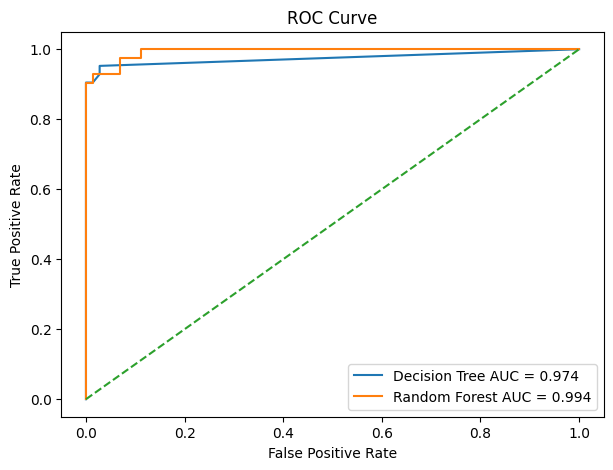

In [ ]:
#ROC,AUC values and curve
dt_probability=dt_best.predict_proba(X_test)[:, 1]
rf_probability=rf_best.predict_proba(X_test)[:, 1]

dt_fpr, dt_tpr, _=roc_curve(y_test, dt_probability)
rf_fpr, rf_tpr, _=roc_curve(y_test, rf_probability)

dt_auc=roc_auc_score(y_test, dt_probability)
rf_auc=roc_auc_score(y_test, rf_probability)

print("Decision Tree AUC:", dt_auc)
print("Random Forest AUC:", rf_auc)

plt.figure(figsize=(7, 5))
plt.plot(dt_fpr,dt_tpr,label="Decision Tree AUC = %.3f" % dt_auc)
plt.plot(rf_fpr,rf_tpr,label="Random Forest AUC = %.3f" % rf_auc)

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [ ]:
#DT,RF classification reports
print("Classification Report - Decision Tree")
print(classification_report(y_test,dt_pred,target_names=["Benign", "Malignant"]))

print("Classification Report - Random Forest")
print(classification_report(y_test,rf_pred,target_names=["Benign", "Malignant"]))

Classification Report - Decision Tree
              precision    recall  f1-score   support

      Benign       0.95      1.00      0.97        72
   Malignant       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114

Classification Report - Random Forest
              precision    recall  f1-score   support

      Benign       0.95      1.00      0.97        72
   Malignant       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114

